# 08. Detection Diagnostics, Threshold Tuning & Visual Inspection

Run this after Notebook 07. It independently loads the available checkpoints and validation split, then:
1. compares confidence/NMS settings on validation data,
2. reports detections per image and detection metrics,
3. visualizes predictions against ground truth,
4. saves the chosen validation settings and example images.

**Do not use the test split for threshold tuning.** This notebook uses validation only.

> **Preprocessing correction:** This notebook uses the exact MobileNetV2 `preprocess_input` transform used by Notebook 06 training. The earlier `/255.0` evaluation preprocessing did not match training and could suppress or distort predictions.

In [1]:

import os, sys, json, math, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import confusion_matrix, classification_report
warnings.filterwarnings("ignore")

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), Path.cwd().parent]
     if (p / "src" / "data" / "dataset.py").exists()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project root not found. Open this notebook from the project root or notebooks folder."
    )
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

DATASET_PATH = PROJECT_ROOT / "data" / "NEU-DET"
BASELINE_PATH = PROJECT_ROOT / "models" / "best_model.keras"
FOCAL_PATH = PROJECT_ROOT / "models" / "focal_experiment" / "best_model_focal.keras"
ANCHORS_PATH = PROJECT_ROOT / "models" / "anchors.npy"
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

CLASS_NAMES = [
    "crazing", "inclusion", "patches",
    "pitted_surface", "rolled-in_scale", "scratches"
]
NUM_CLASSES = len(CLASS_NAMES)
GRID_SIZE = 7
NUM_ANCHORS = 5
IMAGE_SIZE = 224

print("Project:", PROJECT_ROOT)
print("TensorFlow:", tf.__version__)



Project: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow
TensorFlow: 2.15.0


In [2]:

from src.data.dataset import get_dataset_splits

train_samples, val_samples, test_samples = get_dataset_splits(str(DATASET_PATH))
print(f"Train: {len(train_samples)} | Validation: {len(val_samples)} | Test: {len(test_samples)}")

if not ANCHORS_PATH.exists():
    raise FileNotFoundError(f"Missing anchors file: {ANCHORS_PATH}")
anchors = np.load(ANCHORS_PATH).astype(np.float32)
assert anchors.shape == (NUM_ANCHORS, 2), f"Expected anchors shape (5,2), got {anchors.shape}"
print("Anchors:\n", anchors)

def load_image(image_path):
    """
    IMPORTANT: Match Notebook 06 training preprocessing exactly.
    MobileNetV2 preprocess_input maps RGB pixel values from [0, 255] to [-1, 1].
    Do NOT divide by 255 here.
    """
    image = Image.open(image_path).convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))
    image = np.asarray(image, dtype=np.float32)  # keep [0, 255] before preprocessing
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image.astype(np.float32)

def box_iou_xyxy(a, b):
    ax1, ay1, ax2, ay2 = map(float, a)
    bx1, by1, bx2, by2 = map(float, b)
    ix1, iy1 = max(ax1,bx1), max(ay1,by1)
    ix2, iy2 = min(ax2,bx2), min(ay2,by2)
    iw, ih = max(0.0,ix2-ix1), max(0.0,iy2-iy1)
    inter = iw*ih
    area_a = max(0.0,ax2-ax1)*max(0.0,ay2-ay1)
    area_b = max(0.0,bx2-bx1)*max(0.0,by2-by1)
    return inter / (area_a+area_b-inter+1e-9)

def decode_predictions(raw, anchors, conf_threshold=0.25, nms_iou=0.50, max_detections=100):
    raw = np.asarray(raw)
    if raw.ndim == 5:
        raw = raw[0]
    if raw.shape != (GRID_SIZE, GRID_SIZE, NUM_ANCHORS, 5+NUM_CLASSES):
        raise ValueError(f"Unexpected model output shape: {raw.shape}")
    detections = []
    for row in range(GRID_SIZE):
        for col in range(GRID_SIZE):
            for anchor_id in range(NUM_ANCHORS):
                pred = raw[row, col, anchor_id]
                tx, ty, tw, th = pred[:4]
                obj = 1.0 / (1.0 + np.exp(-np.clip(float(pred[4]), -30, 30)))
                cls_logits = pred[5:]
                cls_exp = np.exp(cls_logits - np.max(cls_logits))
                cls_probs = cls_exp / (np.sum(cls_exp) + 1e-9)
                class_id = int(np.argmax(cls_probs))
                score = float(obj * cls_probs[class_id])
                if score < conf_threshold:
                    continue

                # Training encoder stores tx/ty as direct within-cell offsets.
                tx = float(np.clip(tx, 0.0, 1.0))
                ty = float(np.clip(ty, 0.0, 1.0))
                cx = (col + tx) / GRID_SIZE
                cy = (row + ty) / GRID_SIZE
                w = float(anchors[anchor_id,0] * np.exp(np.clip(tw,-5,5)))
                h = float(anchors[anchor_id,1] * np.exp(np.clip(th,-5,5)))
                box = [
                    float(np.clip(cx-w/2,0,1)),
                    float(np.clip(cy-h/2,0,1)),
                    float(np.clip(cx+w/2,0,1)),
                    float(np.clip(cy+h/2,0,1))
                ]
                if box[2] > box[0] and box[3] > box[1]:
                    detections.append({"box":box, "score":score, "class_id":class_id})

    # Class-wise greedy NMS
    kept = []
    for class_id in range(NUM_CLASSES):
        class_dets = sorted(
            [d for d in detections if d["class_id"] == class_id],
            key=lambda x: x["score"], reverse=True
        )
        class_kept = []
        while class_dets:
            best = class_dets.pop(0)
            class_kept.append(best)
            class_dets = [
                d for d in class_dets
                if box_iou_xyxy(best["box"], d["box"]) < nms_iou
            ]
        kept.extend(class_kept)
    kept = sorted(kept, key=lambda x:x["score"], reverse=True)
    return kept[:max_detections]

def get_ground_truth(sample):
    boxes = np.asarray(sample["boxes"], dtype=np.float32).reshape(-1,4)
    labels = np.asarray(sample["labels"], dtype=np.int32).reshape(-1)
    return boxes, labels

def load_model_if_present(path):
    if not path.exists():
        print(f"SKIP - checkpoint not found: {path}")
        return None
    model = tf.keras.models.load_model(path, compile=False)
    print(f"Loaded: {path.name}; output shape: {model.output_shape}")
    return model

def predict_sample(model, sample):
    x = load_image(sample["image"])[None, ...]
    raw = model.predict(x, verbose=0)
    return raw


Train: 1151 | Validation: 288 | Test: 360
Anchors:
 [[0.1828321  0.24619976]
 [0.28540698 0.51598006]
 [0.21671906 0.910609  ]
 [0.6913246  0.32715988]
 [0.81677145 0.9229429 ]]


## 1. Load model(s)

In [3]:

models = {
    "Baseline_BCE": load_model_if_present(BASELINE_PATH),
    "Focal_Loss": load_model_if_present(FOCAL_PATH),
}
models = {k:v for k,v in models.items() if v is not None}
if not models:
    raise FileNotFoundError("No model checkpoints found.")
# Choose the model to inspect. Change this string if needed.
MODEL_NAME = "Focal_Loss" if "Focal_Loss" in models else list(models)[0]
model = models[MODEL_NAME]
print("Selected:", MODEL_NAME)




Loaded: best_model.keras; output shape: (None, 7, 7, 5, 11)
Loaded: best_model_focal.keras; output shape: (None, 7, 7, 5, 11)
Selected: Focal_Loss


## 2. Reuse metric functions from Notebook 07

In [4]:

# These functions intentionally mirror Notebook 07 so this notebook can run independently.
def match_detections(predictions, samples, iou_threshold=0.50):
    tp=fp=fn=0
    for sample,dets in zip(samples,predictions):
        gt_boxes,gt_labels=get_ground_truth(sample); used=set()
        for det in sorted(dets,key=lambda d:d["score"],reverse=True):
            candidates=[(j,box_iou_xyxy(det["box"],gt_boxes[j]))
                        for j in range(len(gt_boxes))
                        if j not in used and int(gt_labels[j])==det["class_id"]]
            best=max(candidates,key=lambda x:x[1],default=(-1,0.0))
            if best[0]>=0 and best[1]>=iou_threshold:
                tp+=1; used.add(best[0])
            else: fp+=1
        fn += len(gt_boxes)-len(used)
    p=tp/(tp+fp+1e-9); r=tp/(tp+fn+1e-9)
    f=2*p*r/(p+r+1e-9)
    return {"TP":tp,"FP":fp,"FN":fn,"precision":p,"recall":r,"f1":f}

def predict_dataset(model, samples, conf, nms):
    output=[]
    for i,s in enumerate(samples):
        output.append(decode_predictions(
            predict_sample(model,s), anchors,
            conf_threshold=conf,nms_iou=nms,max_detections=100
        ))
    return output


## 3. Confidence and NMS sweep

In [5]:

CONF_THRESHOLDS=[0.25,0.40,0.50,0.60,0.70,0.80]
NMS_THRESHOLDS=[0.40,0.50,0.60,0.70]
sweep_rows=[]
prediction_cache={}
for conf in CONF_THRESHOLDS:
    for nms in NMS_THRESHOLDS:
        key=(conf,nms)
        preds=predict_dataset(model,val_samples,conf,nms)
        prediction_cache[key]=preds
        metrics=match_detections(preds,val_samples,0.50)
        counts=[len(x) for x in preds]
        sweep_rows.append({
            "confidence":conf,"nms_iou":nms,
            **metrics,
            "avg_detections_per_image":float(np.mean(counts)),
            "max_detections_per_image":int(np.max(counts))
        })
        print(f"done conf={conf:.2f}, nms={nms:.2f}")
sweep_df=pd.DataFrame(sweep_rows)
display(sweep_df.sort_values(["f1","precision"],ascending=False).head(15).round(4))


done conf=0.25, nms=0.40
done conf=0.25, nms=0.50
done conf=0.25, nms=0.60
done conf=0.25, nms=0.70
done conf=0.40, nms=0.40
done conf=0.40, nms=0.50
done conf=0.40, nms=0.60
done conf=0.40, nms=0.70
done conf=0.50, nms=0.40
done conf=0.50, nms=0.50
done conf=0.50, nms=0.60
done conf=0.50, nms=0.70
done conf=0.60, nms=0.40
done conf=0.60, nms=0.50
done conf=0.60, nms=0.60
done conf=0.60, nms=0.70
done conf=0.70, nms=0.40
done conf=0.70, nms=0.50
done conf=0.70, nms=0.60
done conf=0.70, nms=0.70
done conf=0.80, nms=0.40
done conf=0.80, nms=0.50
done conf=0.80, nms=0.60
done conf=0.80, nms=0.70


,confidence,nms_iou,TP,FP,FN,precision,recall,f1,avg_detections_per_image,max_detections_per_image
13,0.6,0.5,187,761,469,0.1973,0.2851,0.2332,3.2917,22
12,0.6,0.4,173,673,483,0.2045,0.2637,0.2304,2.9375,22
14,0.6,0.6,197,872,459,0.1843,0.3003,0.2284,3.7118,23
15,0.6,0.7,203,975,453,0.1723,0.3095,0.2214,4.0903,23
8,0.5,0.4,253,1565,403,0.1392,0.3857,0.2045,6.3125,27
18,0.7,0.6,95,206,561,0.3156,0.1448,0.1985,1.0451,11
9,0.5,0.5,277,1882,379,0.1283,0.4223,0.1968,7.4965,28
17,0.7,0.5,92,188,564,0.3286,0.1402,0.1966,0.9722,11
19,0.7,0.7,96,227,560,0.2972,0.1463,0.1961,1.1215,11
16,0.7,0.4,88,180,568,0.3284,0.1341,0.1905,0.9306,11


## 4. Select a validation setting

In [6]:

# Best F1 is a diagnostic selection rule, not a guarantee of good real-world performance.
best_row=sweep_df.sort_values(["f1","precision"],ascending=False).iloc[0]
BEST_CONF=float(best_row["confidence"])
BEST_NMS=float(best_row["nms_iou"])
best_predictions=prediction_cache[(BEST_CONF,BEST_NMS)]
print("Selected validation settings:", {"confidence":BEST_CONF,"nms_iou":BEST_NMS})
display(best_row.to_frame("value"))


Selected validation settings: {'confidence': 0.6, 'nms_iou': 0.5}


,value
confidence,0.600000
nms_iou,0.500000
TP,187.000000
FP,761.000000
FN,469.000000
precision,0.197257
recall,0.285061
f1,0.233167
avg_detections_per_image,3.291667
max_detections_per_image,22.000000


## 5. Plot the sweep

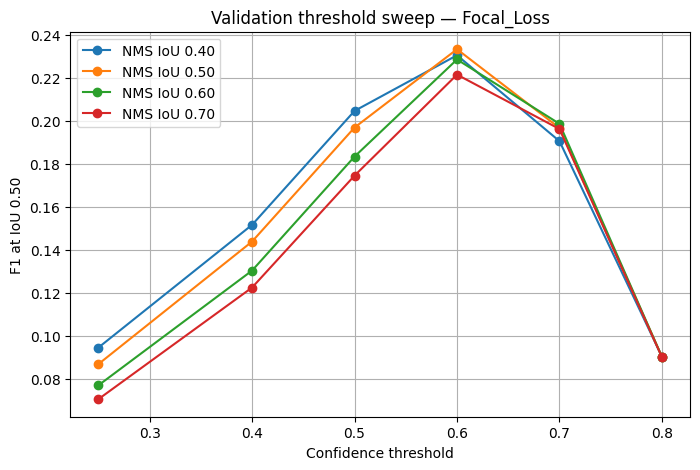

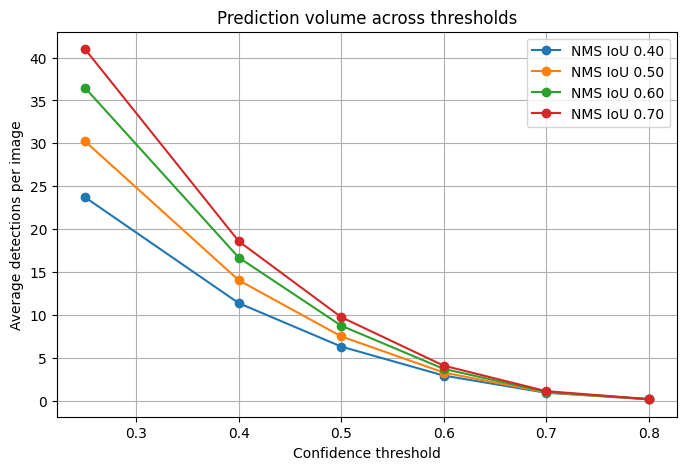

In [7]:

plt.figure(figsize=(8,5))
for nms in NMS_THRESHOLDS:
    part=sweep_df[sweep_df["nms_iou"]==nms].sort_values("confidence")
    plt.plot(part["confidence"],part["f1"],marker="o",label=f"NMS IoU {nms:.2f}")
plt.xlabel("Confidence threshold"); plt.ylabel("F1 at IoU 0.50")
plt.title(f"Validation threshold sweep — {MODEL_NAME}")
plt.grid(True); plt.legend(); plt.show()

plt.figure(figsize=(8,5))
for nms in NMS_THRESHOLDS:
    part=sweep_df[sweep_df["nms_iou"]==nms].sort_values("confidence")
    plt.plot(part["confidence"],part["avg_detections_per_image"],marker="o",label=f"NMS IoU {nms:.2f}")
plt.xlabel("Confidence threshold"); plt.ylabel("Average detections per image")
plt.title("Prediction volume across thresholds")
plt.grid(True); plt.legend(); plt.show()


## 6. Visualize ground truth and predictions

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.8509804..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.8509804..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.88235295..0.9372549].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.88235295..0.9372549].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.7019608..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.7019608..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5529412..0.058823586].
Clipp

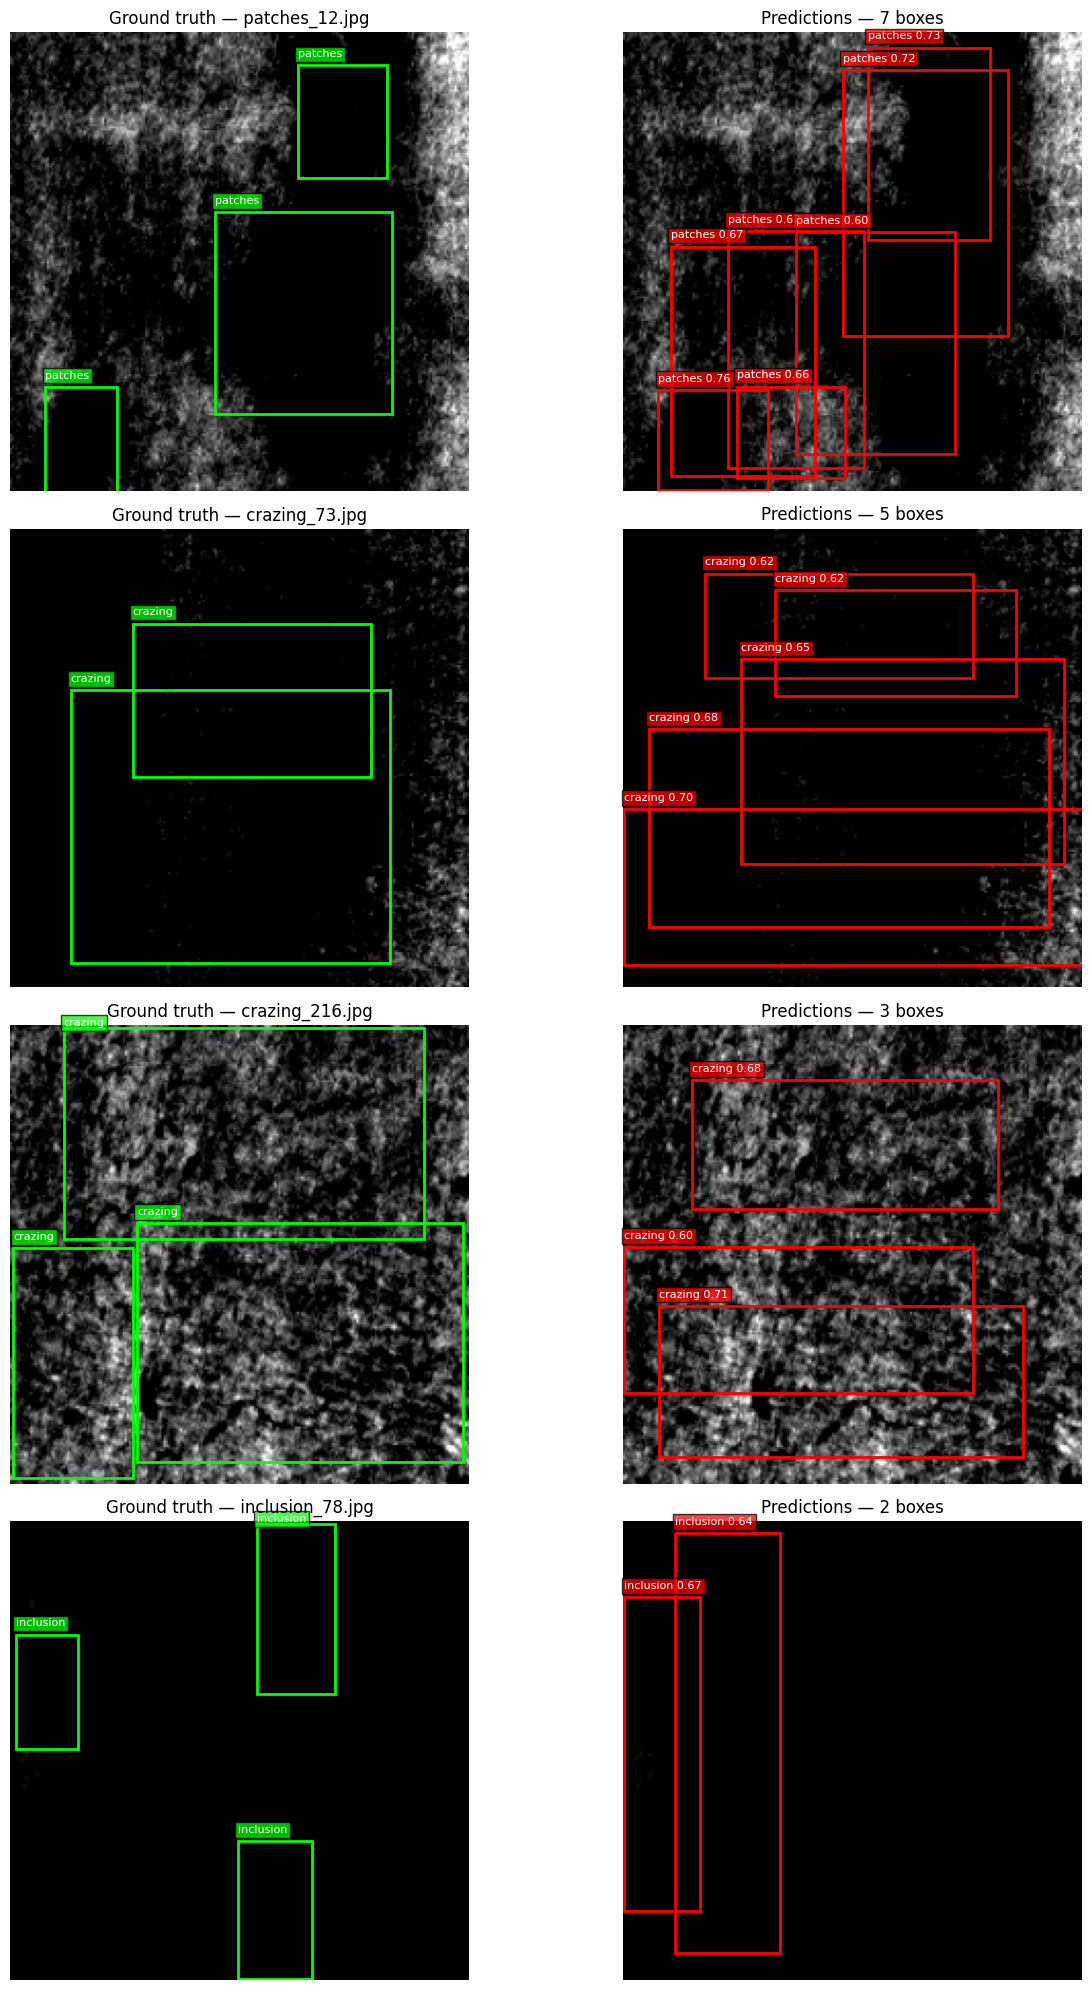

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5686275..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5686275..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.16862744..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.16862744..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.52156866..0.15294123].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.52156866..0.15294123].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.4980392..0.5529412].
Cli

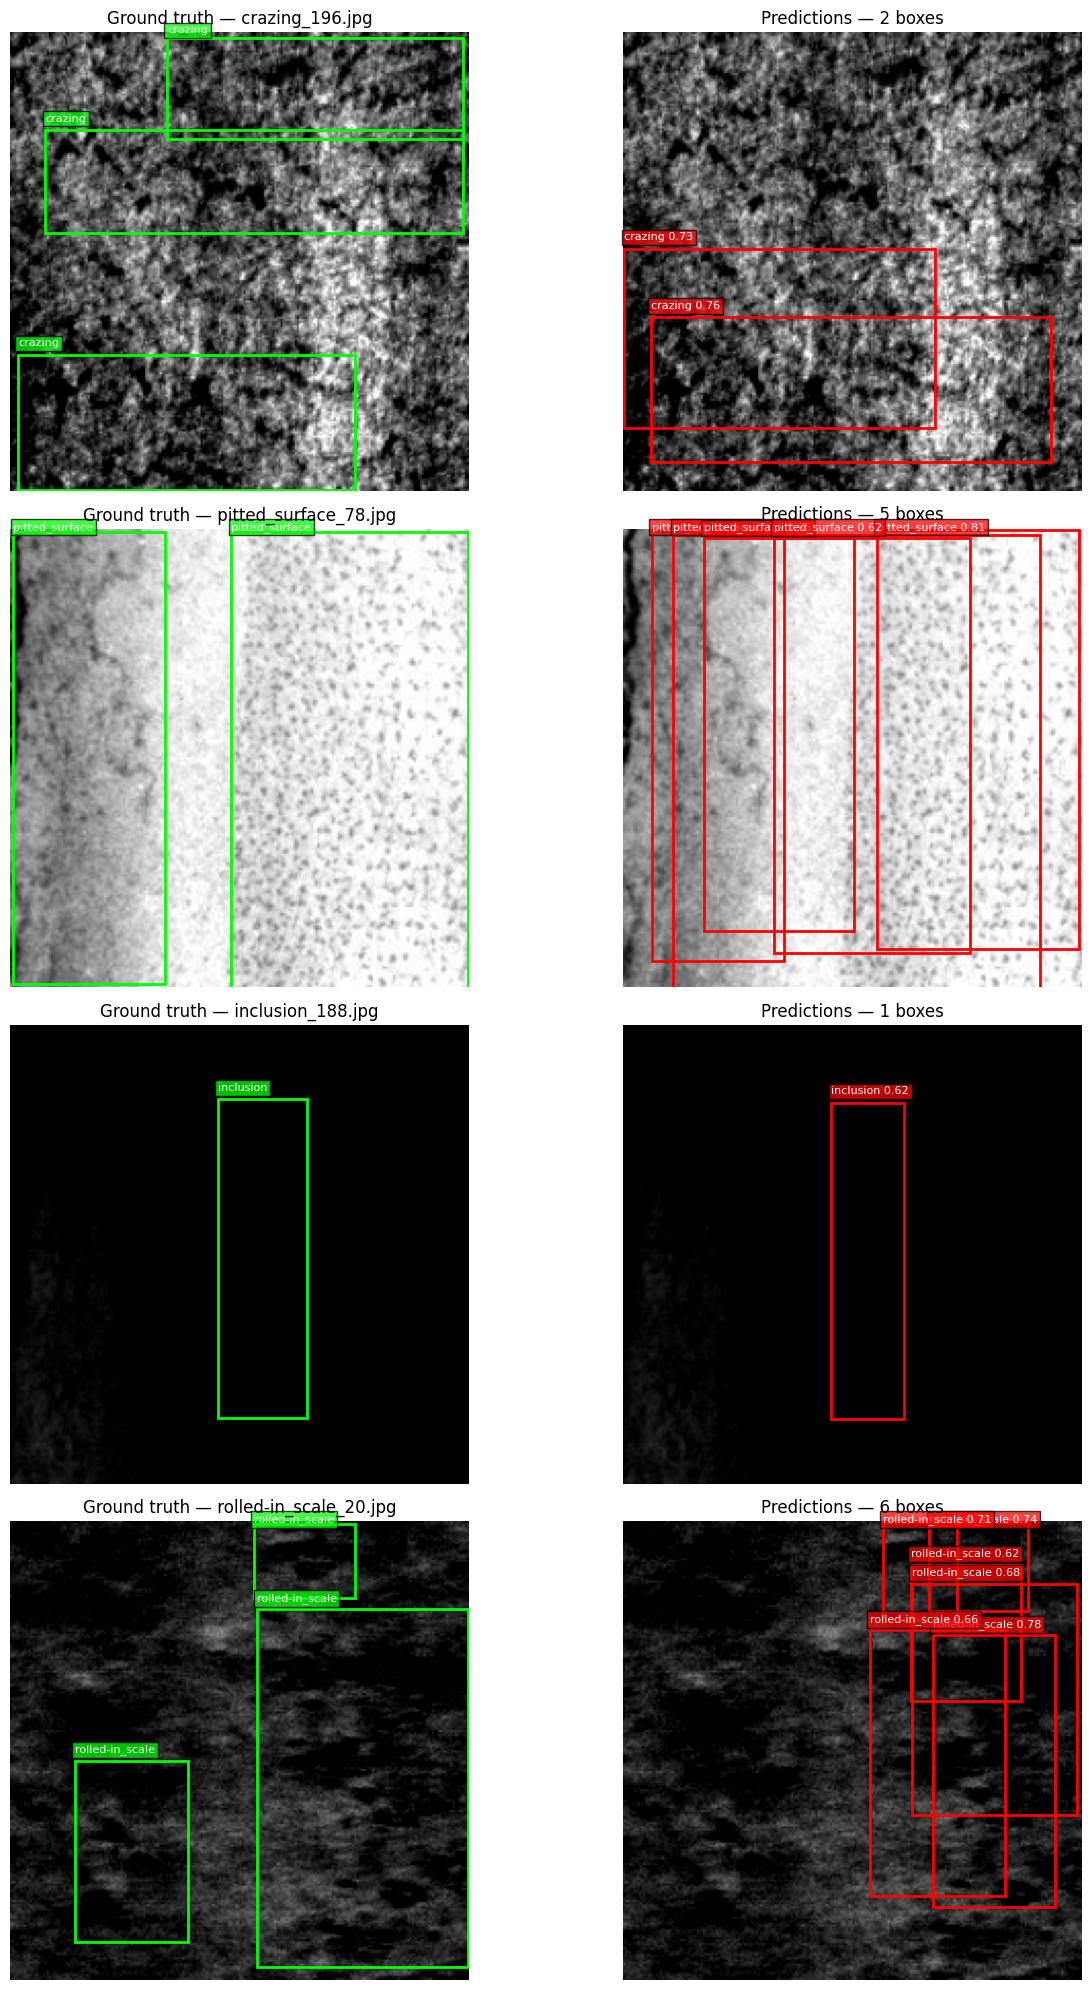

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.4588235..0.9764706].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.4588235..0.9764706].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.41960782..1.0].
Clipping input data to the valid range

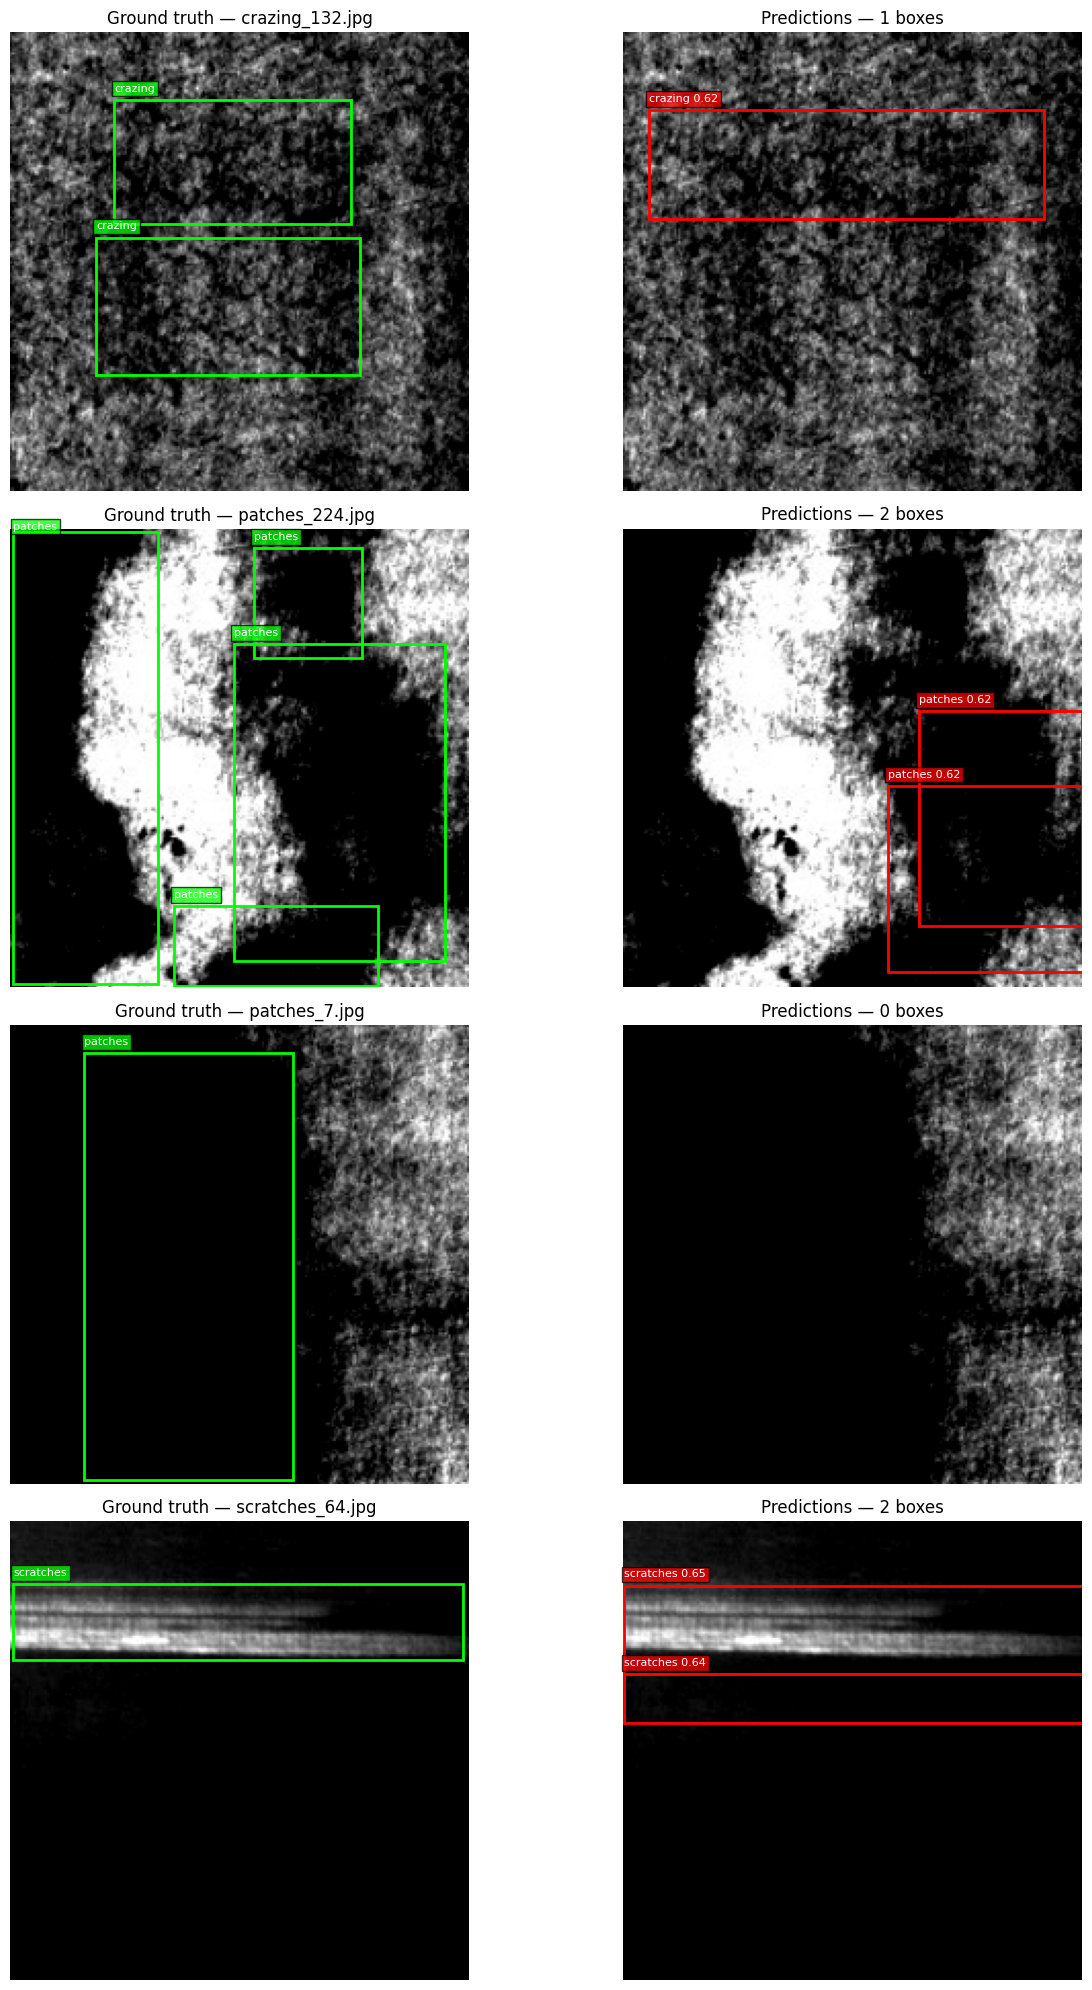

In [8]:

def draw_boxes(ax, image, boxes, labels, color="lime", title=None, scores=None):
    ax.imshow(image)
    h,w=image.shape[:2]
    for i,(box,label) in enumerate(zip(boxes,labels)):
        x1,y1,x2,y2=box
        rect=plt.Rectangle((x1*w,y1*h),(x2-x1)*w,(y2-y1)*h,
                           fill=False,edgecolor=color,linewidth=2)
        ax.add_patch(rect)
        text=CLASS_NAMES[int(label)]
        if scores is not None: text += f" {scores[i]:.2f}"
        ax.text(x1*w,max(0,y1*h-4),text,color="white",fontsize=8,
                bbox=dict(facecolor=color,alpha=.75,pad=2))
    if title: ax.set_title(title)
    ax.axis("off")

# Show first N validation examples; adjust N as needed.
N_SHOW=12
for start in range(0,min(N_SHOW,len(val_samples)),4):
    fig,axes=plt.subplots(4,2,figsize=(14,20))
    for offset in range(4):
        idx=start+offset
        if idx>=min(N_SHOW,len(val_samples)):
            axes[offset,0].axis("off"); axes[offset,1].axis("off"); continue
        sample=val_samples[idx]
        image=load_image(sample["image"])
        gt_boxes,gt_labels=get_ground_truth(sample)
        dets=best_predictions[idx]
        pred_boxes=[d["box"] for d in dets]
        pred_labels=[d["class_id"] for d in dets]
        pred_scores=[d["score"] for d in dets]
        draw_boxes(axes[offset,0],image,gt_boxes,gt_labels,"lime",f"Ground truth — {Path(sample['image']).name}")
        draw_boxes(axes[offset,1],image,pred_boxes,pred_labels,"red",f"Predictions — {len(dets)} boxes",pred_scores)
    plt.tight_layout(); plt.show()


## 7. Inspect false positives and missed objects

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.8509804..1.0].


Image: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\data\NEU-DET\train\images\patches\patches_12.jpg
Ground-truth objects: 3 Predictions: 7
Matched: 1 False positives: 6 Missed: 2
False positive details: [{'class': 'patches', 'score': 0.729, 'box': [0.5311612456846986, 0.031019971057092505, 0.7978839819110395, 0.4493518617905027]}, {'class': 'patches', 'score': 0.723, 'box': [0.47557925116609534, 0.07937395833761424, 0.8351487197746309, 0.6604230037192269]}, {'class': 'patches', 'score': 0.675, 'box': [0.10230043660536758, 0.46478814887675723, 0.4147991652764771, 0.9637832796946714]}, {'class': 'patches', 'score': 0.665, 'box': [0.24531725264844179, 0.7696828629313908, 0.48076078079882384, 0.9678737797882868]}, {'class': 'patches', 'score': 0.618, 'box': [0.22506372423529797, 0.43060758692933554, 0.5211917927706224, 0.9477761006349694]}, {'class': 'patches', 'score': 0.602, 'box': [0.3730103562803312, 0.4323601087013961, 0.7197806

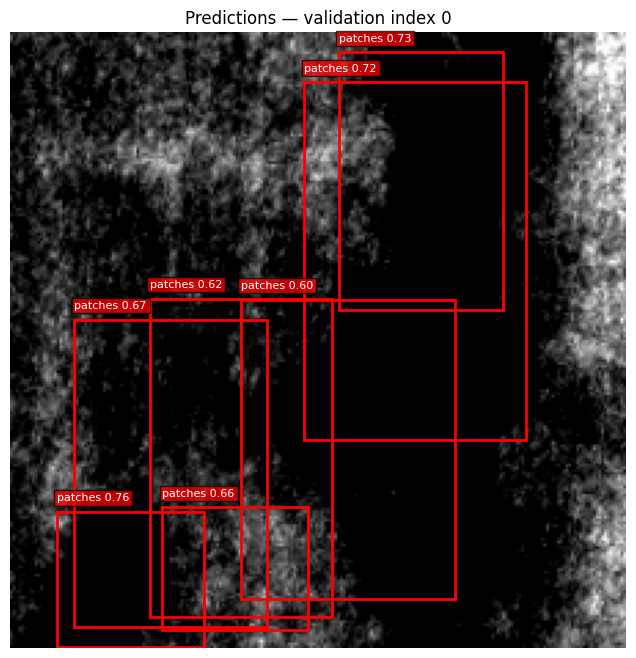

In [9]:

def inspect_image(index):
    sample=val_samples[index]
    gt_boxes,gt_labels=get_ground_truth(sample)
    dets=best_predictions[index]
    used=set(); matched=[]; false_pos=[]
    for det in sorted(dets,key=lambda d:d["score"],reverse=True):
        candidates=[(j,box_iou_xyxy(det["box"],gt_boxes[j]))
                    for j in range(len(gt_boxes))
                    if j not in used and int(gt_labels[j])==det["class_id"]]
        best=max(candidates,key=lambda x:x[1],default=(-1,0.0))
        if best[0]>=0 and best[1]>=0.5:
            used.add(best[0]); matched.append((det,best[1]))
        else:
            false_pos.append(det)
    missed=[j for j in range(len(gt_boxes)) if j not in used]
    print("Image:",sample["image"])
    print("Ground-truth objects:",len(gt_boxes),"Predictions:",len(dets))
    print("Matched:",len(matched),"False positives:",len(false_pos),"Missed:",len(missed))
    print("False positive details:",[
        {"class":CLASS_NAMES[d["class_id"]],"score":round(d["score"],3),"box":d["box"]}
        for d in false_pos[:20]
    ])
    print("Missed ground-truth classes:",[CLASS_NAMES[int(gt_labels[j])] for j in missed])
    fig,ax=plt.subplots(1,1,figsize=(8,8))
    draw_boxes(ax,load_image(sample["image"]),
               [d["box"] for d in dets],[d["class_id"] for d in dets],
               "red",f"Predictions — validation index {index}",
               [d["score"] for d in dets])
    plt.show()

# Change the index to inspect a different validation image.
inspect_image(0)


## 8. Save diagnostics

In [10]:

sweep_path=RESULTS_DIR/f"{MODEL_NAME.lower()}_threshold_nms_sweep.csv"
sweep_df.to_csv(sweep_path,index=False)
settings={
    "model":MODEL_NAME,
    "confidence_threshold":BEST_CONF,
    "nms_iou_threshold":BEST_NMS,
    "matching_iou_threshold":0.50,
    "data_split":"validation",
    "warning":"Do not use these settings as final test results until frozen."
}
settings_path=RESULTS_DIR/f"{MODEL_NAME.lower()}_selected_validation_settings.json"
with open(settings_path,"w",encoding="utf-8") as f:
    json.dump(settings,f,indent=2)
print("Saved:",sweep_path)
print("Saved:",settings_path)


Saved: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\results\focal_loss_threshold_nms_sweep.csv
Saved: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\results\focal_loss_selected_validation_settings.json


In [11]:
# Select one validation image
sample = val_samples[0]

# Prepare image using the current evaluation preprocessing
image = load_image(sample["image"])
raw = model.predict(image[None, ...], verbose=0)

print("Image:", sample["image"])
print("Model output shape:", raw.shape)

# Inspect raw model predictions
pred = raw[0]

objectness_logits = pred[..., 4]
objectness_scores = 1 / (1 + np.exp(-np.clip(objectness_logits, -30, 30)))

class_logits = pred[..., 5:]
class_exp = np.exp(class_logits - np.max(class_logits, axis=-1, keepdims=True))
class_probs = class_exp / (np.sum(class_exp, axis=-1, keepdims=True) + 1e-9)

best_class_probs = np.max(class_probs, axis=-1)
combined_scores = objectness_scores * best_class_probs

print("\nObjectness statistics:")
print("Minimum:", objectness_scores.min())
print("Maximum:", objectness_scores.max())
print("Mean:", objectness_scores.mean())

print("\nCombined confidence statistics:")
print("Minimum:", combined_scores.min())
print("Maximum:", combined_scores.max())
print("Mean:", combined_scores.mean())

print("\nNumber of predictions above thresholds:")
for threshold in [0.01, 0.05, 0.10, 0.20, 0.25, 0.40, 0.50]:
    print(threshold, ":", np.sum(combined_scores >= threshold))

Image: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\data\NEU-DET\train\images\patches\patches_12.jpg
Model output shape: (1, 7, 7, 5, 11)

Objectness statistics:
Minimum: 0.0043005375
Maximum: 0.7559657
Mean: 0.18034892

Combined confidence statistics:
Minimum: 0.0019481045
Maximum: 0.75594604
Mean: 0.17597993

Number of predictions above thresholds:
0.01 : 223
0.05 : 175
0.1 : 133
0.2 : 80
0.25 : 58
0.4 : 33
0.5 : 24


In [12]:
import json

settings_path = RESULTS_DIR / f"{MODEL_NAME.lower()}_selected_validation_settings.json"

with open(settings_path, "r") as f:
    settings = json.load(f)

print(settings)

{'model': 'Focal_Loss', 'confidence_threshold': 0.6, 'nms_iou_threshold': 0.5, 'matching_iou_threshold': 0.5, 'data_split': 'validation', 'warning': 'Do not use these settings as final test results until frozen.'}


In [13]:
for threshold in [0.01, 0.05, 0.10, 0.20, 0.25, 0.40, 0.50, 0.60, 0.70]:
    detections = decode_predictions(
        raw,
        anchors,
        conf_threshold=threshold,
        nms_iou=0.50,
        max_detections=100
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Detections after NMS: {len(detections)}"
    )

Threshold: 0.01 | Detections after NMS: 100
Threshold: 0.05 | Detections after NMS: 93
Threshold: 0.10 | Detections after NMS: 74
Threshold: 0.20 | Detections after NMS: 56
Threshold: 0.25 | Detections after NMS: 47
Threshold: 0.40 | Detections after NMS: 27
Threshold: 0.50 | Detections after NMS: 18
Threshold: 0.60 | Detections after NMS: 7
Threshold: 0.70 | Detections after NMS: 3


## Important notes

- A low F1 or mAP indicates the detector still needs improvement; do not describe it as production-ready.
- The confidence/NMS sweep selects settings on validation data only. Freeze those settings before running final test evaluation.
- If predictions look systematically wrong, first verify that image preprocessing in `load_image()` exactly matches the training pipeline and that the output tensor layout matches `(7, 7, 5, 11)`.
- The decoder intentionally uses direct `tx`/`ty` offsets (clipped to `[0,1]`), because the current target encoder stores offsets directly rather than applying a sigmoid.